# Yarı Zamanlı Çalışmanın Üniversite Öğrencilerinin Akademik Başarısı ve Derse Devamıyla İlişkisi

**Araştırma Yöntem ve Teknikleri, 2026–2027 Güz · Vize çalışması**
**Hazırlayan:** Eren Yeşilcan (360125504)
**Veri:** UCI *Higher Education Students Performance Evaluation* (ikincil veri, CC BY 4.0)

Bu notebook vize raporundaki bütün sayıları ve grafikleri üretir. Hücreleri yukarıdan aşağıya sırayla çalıştırın (Shift+Enter).

> **Yöntem değişikliği notu:** Proje başlangıçta Google Forms anketiyle planlanmıştı. 26 Ekim 2026 tarihli ders duyurusu doğrultusunda katılımcılardan doğrudan veri toplanmamış, araştırma **açık ve hazır bir veri setiyle (ikincil veri analizi)** yeniden düzenlenmiştir.

## A. Veri tanıtımı

| Alan | Bilgi |
|---|---|
| Veri setinin adı | Higher Education Students Performance Evaluation |
| Bağlantı / DOI | https://archive.ics.uci.edu/dataset/856 · https://doi.org/10.24432/C51G82 |
| Oluşturanlar | Nevriye Yılmaz ve Boran Şekeroğlu (Yakın Doğu Üniversitesi), UCI'ye bağış: 14.08.2023 |
| Lisans | Creative Commons Attribution 4.0 (CC BY 4.0): kaynak gösterilerek paylaşılabilir |
| Erişim tarihi | 23.11.2026 |
| Biçim | CSV, 145 satır × 33 sütun, eksik değer yok |
| Bir satır | Bir öğrencinin anket yanıtları ve dönem sonu ders notu (2019, Mühendislik ve Eğitim Bilimleri Fakülteleri) |
| Gerçek mi? | Evet. Gerçek öğrencilerden toplanmış, anonimleştirilmiş veri. Kimlik bilgisi yok (`STUDENT ID` yalnızca sıra numarası). |
| Ölçüm biçimi | Değişkenlerin çoğu **kategorik/sıralı kodlardır** (örn. not ortalaması aralıkları). Bu yüzden ağırlıklı olarak parametrik olmayan testler kullanılır. |

**Bu çalışmada kullanılan değişkenler**

| Kod | Değişken | Kodlar | Rol |
|---|---|---|---|
| 5 | Ek işte çalışma (*Additional work*) | 1 = Evet, 2 = Hayır | Bağımsız |
| 17 | Haftalık ders çalışma süresi | 1 = Hiç, 2 = <5 sa, 3 = 6–10 sa, 4 = 11–20 sa, 5 = >20 sa | Bağımsız / kontrol |
| 22 | Derse devam | 1 = Her zaman, 2 = Bazen, 3 = Hiç | Bağımlı |
| 29 | Son dönem kümülatif not ortalaması (/4.00) | 1 = <2.00, 2 = 2.00–2.49, 3 = 2.50–2.99, 4 = 3.00–3.49, 5 = >3.49 | Bağımlı |
| GRADE | Dönem sonu ders notu | 0 = FF … 7 = AA | Bağımlı |
| COURSE ID | Ders kodu | 1–9 | Kontrol (karıştırıcı) |

## B. Kütüphaneler ve veriyi okuma

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.18, "font.size": 10})

# Renkler: iki grup için sabit sıra (1. mavi = çalışmayan, 2. turuncu = çalışan)
RENK = {"Çalışmıyor": "#2a78d6", "Çalışıyor": "#eb6834"}

KOK = Path("..") if Path("../data").is_dir() else Path(".")   # notebooks/ içinden çalışınca repo kökü
CIKTI = KOK / "outputs"; (CIKTI / "figures").mkdir(parents=True, exist_ok=True); (CIKTI / "tables").mkdir(parents=True, exist_ok=True)
print("Kütüphaneler hazır.")

Kütüphaneler hazır.


Veri dosyası repo içinde `data/` klasöründedir. Colab'da çalışıyorsanız ya repoyu klonlayın ya da CSV dosyasını sol paneldeki **Dosyalar → Yükle** ile ekleyin. Notebook GitHub'daki Colab bağlantısından açıldıysa veri otomatik olarak repodan indirilir. Aşağıdaki hücre bu yolları sırayla dener.

In [2]:
ADAYLAR = [KOK / "data/higher_education_students_performance.csv",
           Path("higher_education_students_performance.csv")]
veri_yolu = next((p for p in ADAYLAR if p.is_file()), None)

GITHUB_CSV = "https://raw.githubusercontent.com/erenyesilcan/arastirma-projesi/main/data/higher_education_students_performance.csv"
if veri_yolu is None:   # Colab'da GitHub linkinden açıldıysa veriyi repodan indir
    try:
        pd.read_csv(GITHUB_CSV, encoding="utf-8-sig").to_csv("higher_education_students_performance.csv", index=False)
        veri_yolu = Path("higher_education_students_performance.csv")
    except Exception as hata:
        print("GitHub'dan indirilemedi:", hata)

if veri_yolu is None:
    try:
        from google.colab import files          # Yalnızca Colab'da çalışır
        yuklenen = files.upload()
        veri_yolu = Path(next(ad for ad in yuklenen if ad.lower().endswith(".csv")))
    except ImportError:
        raise FileNotFoundError("CSV bulunamadı: data/ klasörünü kontrol edin.")

ham = pd.read_csv(veri_yolu, encoding="utf-8-sig")
print("Kaynak dosya:", veri_yolu)
print("Boyut (satır, sütun):", ham.shape)
ham.head()

Kaynak dosya: ../data/higher_education_students_performance.csv
Boyut (satır, sütun): (145, 33)


,STUDENT ID,1,2,3,4,5,6,7,8,9,...,23,24,25,26,27,28,29,30,COURSE ID,GRADE
0,STUDENT1,2,2,3,3,1,2,2,1,1,...,1,1,3,2,1,2,1,1,1,1
1,STUDENT2,2,2,3,3,1,2,2,1,1,...,1,1,3,2,3,2,2,3,1,1
2,STUDENT3,2,2,2,3,2,2,2,2,4,...,1,1,2,2,1,1,2,2,1,1
3,STUDENT4,1,1,1,3,1,2,1,2,1,...,1,2,3,2,2,1,3,2,1,1
4,STUDENT5,2,2,1,3,2,2,1,3,1,...,2,1,2,2,2,1,2,2,1,1


## C. Sütun adlarını düzenleme ve veri kalitesi kontrolü

In [3]:
AD = {"STUDENT ID": "ogrenci_no", "1": "yas_grubu", "2": "cinsiyet", "5": "ek_is",
      "17": "haftalik_calisma", "22": "devam", "29": "kum_gno", "30": "beklenen_gno",
      "COURSE ID": "ders", "GRADE": "not_kodu"}
veri = ham.rename(columns=AD)[list(AD.values())].copy()

# Analiz için anlaşılır değişkenler
veri["calisma_durumu"] = np.where(veri["ek_is"] == 1, "Çalışıyor", "Çalışmıyor")
veri["calisiyor"] = (veri["ek_is"] == 1).astype(int)
veri["derse_her_zaman"] = (veri["devam"] == 1).astype(int)          # 1 = her zaman devam
veri["gno_3_ustu"] = (veri["kum_gno"] >= 4).astype(int)             # 1 = GNO ≥ 3.00

print("Eksik değer sayısı:", int(veri.isna().sum().sum()))
print("Tekrarlı satır:", int(veri.duplicated().sum()))
for s, (a, b) in {"ek_is": (1, 2), "haftalik_calisma": (1, 5), "devam": (1, 3),
                  "kum_gno": (1, 5), "not_kodu": (0, 7)}.items():
    assert veri[s].between(a, b).all(), f"{s} beklenen aralık dışında"
assert len(veri) == 145
print("Kontroller başarılı: 145 öğrenci, kodlar beklenen aralıklarda.")
veri.head()

Eksik değer sayısı: 0
Tekrarlı satır: 0
Kontroller başarılı: 145 öğrenci, kodlar beklenen aralıklarda.


,ogrenci_no,yas_grubu,cinsiyet,ek_is,haftalik_calisma,devam,kum_gno,beklenen_gno,ders,not_kodu,calisma_durumu,calisiyor,derse_her_zaman,gno_3_ustu
0,STUDENT1,2,2,1,3,1,1,1,1,1,Çalışıyor,1,1,0
1,STUDENT2,2,2,1,2,1,2,3,1,1,Çalışıyor,1,1,0
2,STUDENT3,2,2,2,2,1,2,2,1,1,Çalışmıyor,0,1,0
3,STUDENT4,1,1,1,3,1,3,2,1,1,Çalışıyor,1,1,0
4,STUDENT5,2,2,2,2,1,2,2,1,1,Çalışmıyor,0,1,0


## D. Betimsel istatistik (toplam, oran, ortalama)

In [4]:
n = len(veri)
n_cal = int(veri["calisiyor"].sum())
print(f"Toplam öğrenci: {n}")
print(f"Ek işte çalışan: {n_cal} (%{100*n_cal/n:.1f}) · Çalışmayan: {n-n_cal} (%{100*(n-n_cal)/n:.1f})")

ETIKET_GNO = {1: "<2.00", 2: "2.00–2.49", 3: "2.50–2.99", 4: "3.00–3.49", 5: ">3.49"}
ETIKET_CAL = {1: "Hiç", 2: "<5 sa", 3: "6–10 sa", 4: "11–20 sa", 5: ">20 sa"}
ETIKET_DEV = {1: "Her zaman", 2: "Bazen", 3: "Hiç"}
ETIKET_NOT = {0: "FF", 1: "DD", 2: "DC", 3: "CC", 4: "CB", 5: "BB", 6: "BA", 7: "AA"}

ozet = (veri.groupby("calisma_durumu")
        .agg(n=("ogrenci_no", "size"),
             kum_gno_kod_ort=("kum_gno", "mean"), kum_gno_medyan=("kum_gno", "median"),
             not_kod_ort=("not_kodu", "mean"), not_medyan=("not_kodu", "median"),
             haftalik_calisma_ort=("haftalik_calisma", "mean"),
             her_zaman_devam_oran=("derse_her_zaman", "mean"),
             gno_3_ustu_oran=("gno_3_ustu", "mean"))
        .round(3))
ozet.to_csv(CIKTI / "tables/betimsel_ozet.csv", encoding="utf-8-sig")
ozet

Toplam öğrenci: 145
Ek işte çalışan: 49 (%33.8) · Çalışmayan: 96 (%66.2)


,n,kum_gno_kod_ort,kum_gno_medyan,not_kod_ort,not_medyan,haftalik_calisma_ort,her_zaman_devam_oran,gno_3_ustu_oran
calisma_durumu,,,,,,,,
Çalışmıyor,96,3.156,3.0,3.490,3.0,2.125,0.750,0.458
Çalışıyor,49,3.061,3.0,2.714,2.0,2.347,0.776,0.429


In [5]:
def yuzde_tablo(sutun, etiket):
    t = pd.crosstab(veri[sutun].map(etiket), veri["calisma_durumu"], normalize="columns").mul(100).round(1)
    return t.reindex([etiket[k] for k in sorted(etiket) if etiket[k] in t.index])

tablolar = {"kum_gno": yuzde_tablo("kum_gno", ETIKET_GNO), "not": yuzde_tablo("not_kodu", ETIKET_NOT),
            "devam": yuzde_tablo("devam", ETIKET_DEV), "haftalik_calisma": yuzde_tablo("haftalik_calisma", ETIKET_CAL)}
for ad, t in tablolar.items():
    t.to_csv(CIKTI / f"tables/yuzde_{ad}.csv", encoding="utf-8-sig")
    print(f"\n% dağılım: {ad}\n", t)


% dağılım: kum_gno
 calisma_durumu  Çalışmıyor  Çalışıyor
kum_gno                              
<2.00                 10.4       14.3
2.00–2.49             27.1       24.5
2.50–2.99             16.7       18.4
3.00–3.49             28.1       26.5
>3.49                 17.7       16.3

% dağılım: not
 calisma_durumu  Çalışmıyor  Çalışıyor
not_kodu                             
FF                     3.1       10.2
DD                    22.9       26.5
DC                    16.7       16.3
CC                    14.6       14.3
CB                     4.2       12.2
BB                    13.5        8.2
BA                    10.4        6.1
AA                    14.6        6.1

% dağılım: devam
 calisma_durumu  Çalışmıyor  Çalışıyor
devam                                
Her zaman             75.0       77.6
Bazen                 25.0       22.4

% dağılım: haftalik_calisma
 calisma_durumu    Çalışmıyor  Çalışıyor
haftalik_calisma                       
Hiç                     19.8       

## E. Grafikler

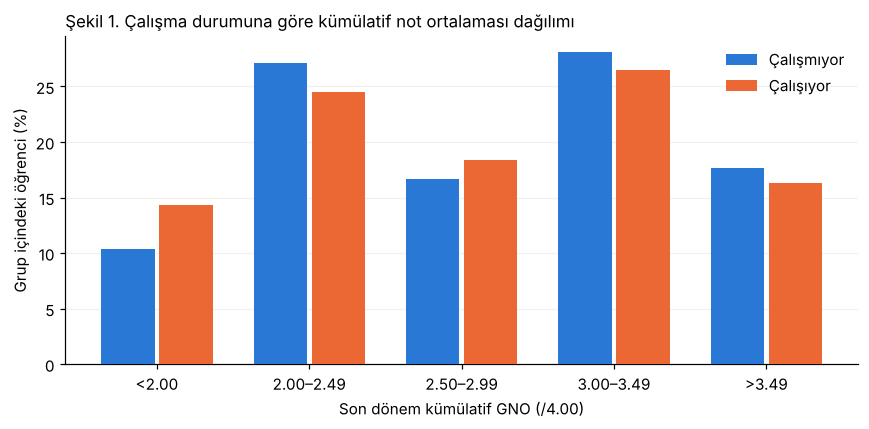

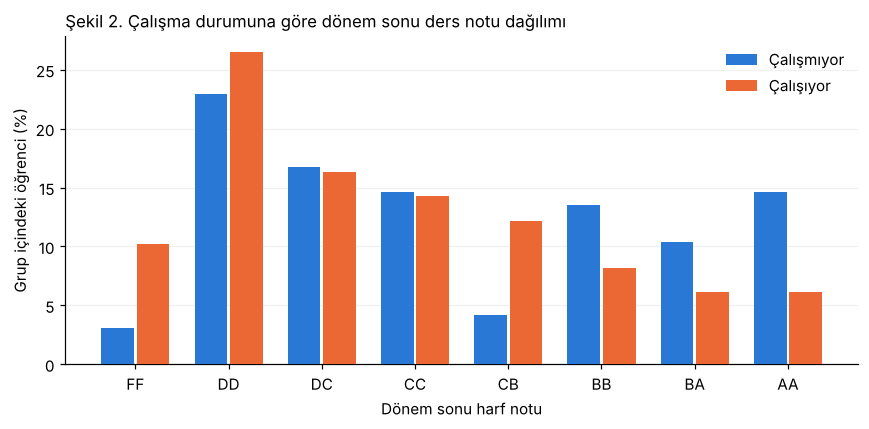

In [6]:
def grup_cubuk(tablo, baslik, xetiket, dosya):
    fig, ax = plt.subplots(figsize=(8, 4))
    x = np.arange(len(tablo.index)); w = 0.38
    for i, grup in enumerate(["Çalışmıyor", "Çalışıyor"]):
        ax.bar(x + (i - 0.5) * w, tablo[grup], width=w - 0.03, color=RENK[grup], label=grup, zorder=3)
    ax.set_xticks(x, tablo.index); ax.set_xlabel(xetiket); ax.set_ylabel("Grup içindeki öğrenci (%)")
    ax.set_title(baslik, loc="left", fontsize=11); ax.legend(frameon=False); ax.grid(axis="x", visible=False)
    fig.tight_layout(); fig.savefig(CIKTI / "figures" / dosya, dpi=200); plt.show()

grup_cubuk(tablolar["kum_gno"], "Şekil 1. Çalışma durumuna göre kümülatif not ortalaması dağılımı",
           "Son dönem kümülatif GNO (/4.00)", "sekil1_gno_dagilimi.png")
grup_cubuk(tablolar["not"], "Şekil 2. Çalışma durumuna göre dönem sonu ders notu dağılımı",
           "Dönem sonu harf notu", "sekil2_ders_notu_dagilimi.png")

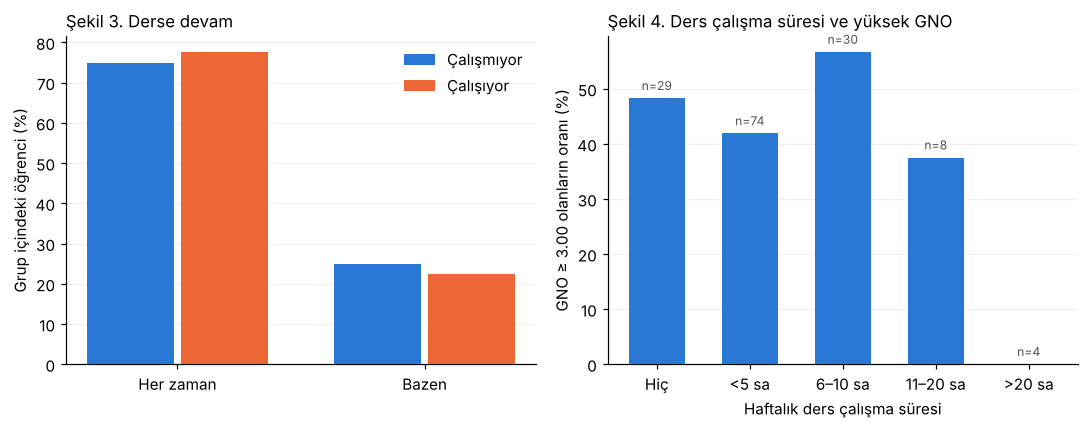

In [7]:
# Şekil 3: Derse devam (yüzde) · Şekil 4: Haftalık ders çalışma süresine göre GNO ≥ 3.00 oranı
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
dev = tablolar["devam"]
x = np.arange(len(dev.index)); w = 0.38
for i, g in enumerate(["Çalışmıyor", "Çalışıyor"]):
    axes[0].bar(x + (i - 0.5) * w, dev[g], width=w - 0.03, color=RENK[g], label=g, zorder=3)
axes[0].set_xticks(x, dev.index); axes[0].set_ylabel("Grup içindeki öğrenci (%)")
axes[0].set_title("Şekil 3. Derse devam", loc="left", fontsize=11); axes[0].legend(frameon=False)
axes[0].grid(axis="x", visible=False)

oran = (veri.groupby("haftalik_calisma")["gno_3_ustu"].agg(["mean", "size"]))
axes[1].bar([ETIKET_CAL[k] for k in oran.index], oran["mean"] * 100, color="#2a78d6", zorder=3, width=0.6)
for i, (m, s) in enumerate(zip(oran["mean"], oran["size"])):
    axes[1].text(i, m * 100 + 1.5, f"n={s}", ha="center", fontsize=8, color="#52514e")
axes[1].set_ylabel("GNO ≥ 3.00 olanların oranı (%)"); axes[1].set_xlabel("Haftalık ders çalışma süresi")
axes[1].set_title("Şekil 4. Ders çalışma süresi ve yüksek GNO", loc="left", fontsize=11)
axes[1].grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(CIKTI / "figures/sekil3_4_devam_calisma_suresi.png", dpi=200); plt.show()

## F. Hipotez testleri

**Neden bu testler?** Not ortalaması ve ders notu *sıralı kategorik* kodlar olduğu için iki grubu karşılaştırmada **Mann–Whitney U testi** ana test olarak kullanılır. Karşılaştırma amacıyla **Welch t-testi** de raporlanır (değişkenler gerçek sürekli ölçüm olmadığı için yalnızca destekleyici bilgi niteliğindedir). Kategorik × kategorik ilişkilerde **ki-kare / Fisher kesin testi**, sıralı değişkenler arası ilişkide **Spearman sıra korelasyonu** kullanılır. Anlamlılık düzeyi α = 0,05 (çift yönlü).

- **H₁ₐ:** Ek işte çalışan öğrencilerin kümülatif not ortalaması çalışmayanlardan farklıdır. **H₀ₐ:** Fark yoktur.
- **H₁ᵦ:** Çalışan ve çalışmayan öğrencilerin dönem sonu ders notları farklıdır. **H₀ᵦ:** Fark yoktur.
- **H₁ᶜ:** Derse devam durumu çalışma durumuna göre farklılaşır. **H₀ᶜ:** Farklılaşmaz.
- **H₁ᵈ:** Haftalık ders çalışma süresi ve derse devam, not ortalamasıyla ilişkilidir. **H₀ᵈ:** İlişki yoktur.

In [8]:
cal = veri[veri["calisiyor"] == 1]; cmy = veri[veri["calisiyor"] == 0]
sonuclar = []

def iki_grup(sutun, ad):
    u = stats.mannwhitneyu(cal[sutun], cmy[sutun], alternative="two-sided")
    r_rb = 1 - 2 * u.statistic / (len(cal) * len(cmy))        # rank-biserial etki büyüklüğü
    t = stats.ttest_ind(cal[sutun], cmy[sutun], equal_var=False)
    sonuclar.append({"hipotez": ad, "test": "Mann–Whitney U", "istatistik": round(float(u.statistic), 1),
                     "p": round(float(u.pvalue), 4), "etki": f"r_rb = {r_rb:.3f}",
                     "ek_bilgi": f"Welch t = {t.statistic:.2f}, p = {t.pvalue:.4f}; ort. çalışan {cal[sutun].mean():.2f} / çalışmayan {cmy[sutun].mean():.2f}"})

iki_grup("kum_gno", "H_a: Kümülatif GNO")
iki_grup("not_kodu", "H_b: Dönem sonu ders notu")

ct = pd.crosstab(veri["calisma_durumu"], veri["devam"])
odds, p_f = stats.fisher_exact(ct.values)
sonuclar.append({"hipotez": "H_c: Derse devam × çalışma", "test": "Fisher kesin testi (2×2)",
                 "istatistik": round(float(odds), 3), "p": round(float(p_f), 4), "etki": f"OR = {odds:.2f}",
                 "ek_bilgi": "Veride 'hiç devam etmeyen' öğrenci yok; tablo 2×2"})

for x_, ad in [("haftalik_calisma", "H_d: Haftalık ders çalışma × GNO"), ("derse_her_zaman", "H_d: Her zaman devam × GNO")]:
    r = stats.spearmanr(veri[x_], veri["kum_gno"])
    sonuclar.append({"hipotez": ad, "test": "Spearman ρ", "istatistik": round(float(r.statistic), 3),
                     "p": round(float(r.pvalue), 4), "etki": f"ρ = {r.statistic:.3f}", "ek_bilgi": ""})

u2 = stats.mannwhitneyu(cal["haftalik_calisma"], cmy["haftalik_calisma"], alternative="two-sided")
sonuclar.append({"hipotez": "Ek: Ders çalışma süresi × çalışma durumu", "test": "Mann–Whitney U",
                 "istatistik": round(float(u2.statistic), 1), "p": round(float(u2.pvalue), 4), "etki": "", "ek_bilgi": ""})

sonuc_tablo = pd.DataFrame(sonuclar)
sonuc_tablo["karar (α=0,05)"] = np.where(sonuc_tablo["p"] < 0.05, "H₀ reddedildi", "H₀ reddedilemedi")
sonuc_tablo.to_csv(CIKTI / "tables/hipotez_testleri.csv", index=False, encoding="utf-8-sig")
sonuc_tablo

,hipotez,test,istatistik,p,etki,ek_bilgi,"karar (α=0,05)"
0,H_a: Kümülatif GNO,Mann–Whitney U,2258.500,0.6899,r_rb = 0.040,"Welch t = -0.41, p = 0.6820; ort. çalışan 3.06...",H₀ reddedilemedi
1,H_b: Dönem sonu ders notu,Mann–Whitney U,1891.500,0.0514,r_rb = 0.196,"Welch t = -2.10, p = 0.0383; ort. çalışan 2.71...",H₀ reddedilemedi
2,H_c: Derse devam × çalışma,Fisher kesin testi (2×2),0.868,0.8385,OR = 0.87,Veride 'hiç devam etmeyen' öğrenci yok; tablo 2×2,H₀ reddedilemedi
3,H_d: Haftalık ders çalışma × GNO,Spearman ρ,0.046,0.5804,ρ = 0.046,,H₀ reddedilemedi
4,H_d: Her zaman devam × GNO,Spearman ρ,0.179,0.0308,ρ = 0.179,,H₀ reddedildi
5,Ek: Ders çalışma süresi × çalışma durumu,Mann–Whitney U,2599.500,0.2628,,,H₀ reddedilemedi


### Karıştırıcı değişken kontrolü: ders (COURSE ID)

Dönem sonu notları **farklı derslerden** gelir ve çalışan/çalışmayan öğrenciler derslere eşit dağılmamıştır. Bu nedenle H_b testinin sonucu dersten kaynaklanıyor olabilir. Aşağıda en kalabalık ders (Ders 1) içinde aynı karşılaştırma tekrarlanır.

In [9]:
print(pd.crosstab(veri["ders"], veri["calisma_durumu"]))
d1 = veri[veri["ders"] == 1]
u_d1 = stats.mannwhitneyu(d1.loc[d1.calisiyor == 1, "not_kodu"], d1.loc[d1.calisiyor == 0, "not_kodu"], alternative="two-sided")
print(f"\nDers 1 içinde (n={len(d1)}; çalışan {int(d1.calisiyor.sum())}): "
      f"not ort. çalışan {d1.loc[d1.calisiyor==1,'not_kodu'].mean():.2f} / çalışmayan {d1.loc[d1.calisiyor==0,'not_kodu'].mean():.2f}, "
      f"Mann–Whitney p = {u_d1.pvalue:.4f}")

calisma_durumu  Çalışmıyor  Çalışıyor
ders                                 
1                       46         20
2                        1          1
3                        7          1
4                        3          1
5                        3          4
6                        6          2
7                       11          4
8                        9          5
9                       10         11

Ders 1 içinde (n=66; çalışan 20): not ort. çalışan 1.95 / çalışmayan 2.43, Mann–Whitney p = 0.2342


## G. Keşif amaçlı makine öğrenmesi denemesi (7. hafta uygulaması)

7. haftada öğrenilen **karar ağacı** yöntemiyle, yalnızca üç değişkenden (ek işte çalışma, haftalık ders çalışma süresi, derse devam) öğrencinin GNO'sunun 3.00 ve üzeri olup olmadığı tahmin edilmeye çalışılır. Veri küçük olduğu için tek bir eğitim/test bölmesi yerine **5 katlı tabakalı çapraz doğrulama** kullanılır. Model, her zaman çoğunluk sınıfını tahmin eden basit bir **temel modelle** karşılaştırılır. Bu bölüm hipotez testi değildir, yalnızca keşif amaçlıdır.

In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

X = veri[["calisiyor", "haftalik_calisma", "derse_her_zaman"]]
y = veri["gno_3_ustu"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
agac = cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=42), X, y, cv=cv, scoring="accuracy")
temel = cross_val_score(DummyClassifier(strategy="most_frequent"), X, y, cv=cv, scoring="accuracy")
print(f"GNO ≥ 3.00 oranı: %{100*y.mean():.1f}")
print(f"Karar ağacı doğruluğu (5 kat ort.): %{100*agac.mean():.1f} ± {100*agac.std():.1f}")
print(f"Temel model (çoğunluk sınıfı):      %{100*temel.mean():.1f} ± {100*temel.std():.1f}")
ml = {"agac_dogruluk": round(float(agac.mean()), 4), "agac_std": round(float(agac.std()), 4),
      "temel_dogruluk": round(float(temel.mean()), 4)}

GNO ≥ 3.00 oranı: %44.8
Karar ağacı doğruluğu (5 kat ort.): %49.7 ± 3.5
Temel model (çoğunluk sınıfı):      %55.2 ± 0.0


## H. Sonuçların kaydedilmesi

In [11]:
rapor = {
    "veri_kaynagi": "UCI Higher Education Students Performance Evaluation, DOI 10.24432/C51G82, CC BY 4.0",
    "erisim_tarihi": "2026-11-23",
    "n": n, "calisan": n_cal, "calisan_oran": round(n_cal / n, 4),
    "testler": sonuclar, "makine_ogrenmesi": ml,
}
with open(CIKTI / "sonuc.json", "w", encoding="utf-8") as f:
    json.dump(rapor, f, ensure_ascii=False, indent=2, default=float)
print("Kaydedilen dosyalar:")
for p in sorted(CIKTI.rglob("*")):
    if p.is_file(): print(" -", p)

Kaydedilen dosyalar:
 - ../outputs/figures/sekil1_gno_dagilimi.png
 - ../outputs/figures/sekil2_ders_notu_dagilimi.png
 - ../outputs/figures/sekil3_4_devam_calisma_suresi.png
 - ../outputs/sonuc.json
 - ../outputs/tables/betimsel_ozet.csv
 - ../outputs/tables/hipotez_testleri.csv
 - ../outputs/tables/yuzde_devam.csv
 - ../outputs/tables/yuzde_haftalik_calisma.csv
 - ../outputs/tables/yuzde_kum_gno.csv
 - ../outputs/tables/yuzde_not.csv


## I. Akademik yorum

Örneklemdeki 145 öğrencinin yaklaşık üçte biri (%33,8) ek bir işte çalışmaktadır. Çalışan ve çalışmayan öğrencilerin **kümülatif not ortalaması dağılımları birbirine çok benzerdir** ve aralarında anlamlı fark bulunmamıştır. **Dönem sonu ders notunda** çalışanların ortalaması daha düşük görünmektedir, ancak ana test olan Mann–Whitney U sonucu sınırda kalmıştır (p ≈ 0,05). En kalabalık ders içinde bakıldığında fark aynı yönde kalmakla birlikte anlamlı değildir. Bu nedenle bulgu kesin bir sonuç olarak değil, final aşamasında incelenecek bir ipucu olarak yorumlanmalıdır. Derse devam açısından iki grup benzerdir. Derse *her zaman* devam etmek ise daha yüksek not ortalamasıyla zayıf ama anlamlı biçimde ilişkilidir. Haftalık ders çalışma süresi ile not ortalaması arasında ilişki görülmemiştir. Keşif amaçlı karar ağacı modeli de bu üç değişkenle yüksek GNO'yu temel modelden daha iyi tahmin edememiştir. Bu durum, başarıyı açıklamak için başka değişkenlere ihtiyaç olduğunu düşündürmektedir.

**Sınırlılıklar:** Veri 2019'da Kıbrıs'taki tek bir üniversiteden ve 145 öğrenciden oluşur. Ek işte çalışma yalnızca evet/hayır olarak ölçülmüştür, **haftalık çalışma saati** veride yoktur. Değişkenler öz bildirime dayalı ve aralık kodludur. Kesitsel bir veri olduğundan bulgular **neden-sonuç ilişkisi kanıtlamaz**.

## J. Teslim kontrolü (6. hafta şablonu)
- [x] Çalışır .ipynb dosyası
- [x] CSV verisi + kaynak, lisans, erişim tarihi
- [x] Birimler ve kodların açıklaması
- [x] Toplam, oran ve ortalama hesabı
- [x] Açıklamalı grafikler (Şekil 1–4)
- [x] 4–5 cümlelik akademik yorum
- [x] Sonuç dosyaları (CSV, JSON, PNG)
- [x] Gizli/kişisel veri ve anahtar yok